**Live Deployment Link:** https://diamond-price-hunain.streamlit.app/

# Diamond Price Prediction System – 10-Fold Cross Validation (Full Dataset)

**Course:** Machine Learning Fundamentals (AIC354) | **Assignment 3** | **Student:** Muhammad Hunain (FA24-BSE-083), Section B | **Instructor:** Dr. Rao Muhammad Adeel Nawab

## Setup: Running This Notebook on Google Colab

Nothing needs to be installed, Colab already has every library used here.

1. Open **https://colab.research.google.com** and sign in.
2. **File → Upload notebook** and pick this `.ipynb` file.
3. **Runtime → Run all**.
4. When **Step 2.1** runs, click **Choose Files** and select **`diamonds.csv`**. The rest runs on its own.

> Colab deletes uploaded files when the runtime resets. If you see a *file not found* error, run Step 2.1 again and re-upload `diamonds.csv`.

---

## Introduction

##### **Definition** A regression task that predicts the **price (in US dollars)** of a diamond from its physical properties: carat weight, cut, colour, clarity, depth, table and its x/y/z dimensions.
##### **Application** Jewellery pricing, insurance valuation, online diamond marketplaces, pawn shops and resale appraisal.

### Why I picked this problem

For Task 2 the problem had to be similar to the Car Price system, so I wanted a **regression** problem with a **large real-world dataset**, a mix of **numeric and text (categorical) features**, and a **skewed price** with some very expensive items. Diamond price prediction fits all of these:

| | Car Price (instructor) | Diamond Price (this notebook) |
|---|---|---|
| Task | Regression (predict MSRP) | Regression (predict price) |
| Rows | about 11,900 | **53,940** (about 4.5 times larger) |
| Numeric features | Engine HP, Year, Cylinders, MPG... | carat, depth, table, x, y, z |
| Categorical features | Market Category, Vehicle Style | cut, colour, clarity |
| Skewed target | yes (supercars) | yes (very large stones) |

**Dataset source:** the classic *diamonds* dataset (53,940 diamonds, 10 columns), published in the `seaborn-data` repository on GitHub: https://github.com/mwaskom/seaborn-data (file `diamonds.csv`). It is the full dataset, not a sample.

### Aim of This Notebook

> **Which of 5 regression algorithms predicts diamond prices best, and can the best one actually be deployed to the cloud?**

The instructor's Car Price notebook compared Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting. The assignment says to use algorithms that were **not** used there, so I use these five:

| # | Algorithm | Why it is different from the car notebook |
|---|---|---|
| 1 | **Ridge Regression** | A linear model, but with an L2 penalty that shrinks the weights (plain Linear Regression has no penalty) |
| 2 | **AdaBoost** | Boosting with many tiny trees where each new tree focuses on the cars the previous ones got wrong |
| 3 | **Extra Trees** | Like Random Forest but the split points are chosen at random, which makes it faster and often smoother |
| 4 | **Hist Gradient Boosting** | A modern, histogram-based gradient boosting (the idea behind LightGBM) that is very fast on big data |
| 5 | **Neural Network (MLP)** | A small multi-layer perceptron with two hidden layers |

All five come from scikit-learn and use (almost) default settings, so no tuning is hiding behind the results.

### What is K-Fold Cross Validation?

One train/test split can be lucky or unlucky, depending on which diamonds land in the test set. K-fold removes that luck:

1. Shuffle the data and cut it into **K equal folds** (here K = 10).
2. Train on **K−1 folds**, test on the remaining one.
3. Repeat K times so every fold is the test set once.
4. Report the **mean and standard deviation** of the K scores.

### What is RMSE?

**Root Mean Squared Error** = square root of the average of the squared errors. It is in the same unit as the target (dollars), so an RMSE of $540 means a typical prediction is off by roughly $540. Because errors are squared, a few big mistakes on very expensive diamonds hurt it much more than many small ones. **Lower is better.**

# Code – Diamond Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import pickle
import time

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (none of them are in the Car Price notebook) ---
from sklearn.linear_model import Ridge
from sklearn.ensemble import AdaBoostRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.5.3
  Pandas       : 3.0.5
  scikit-learn : 1.9.1
  Matplotlib   : 3.11.2


# Step 2: Load Sample Data
## Step 2.1: Upload the Dataset (Google Colab)

In Colab a **Choose Files** button appears below the next cell. Select **`diamonds.csv`**. If the file is already in the folder (for example when running on your own computer) the upload is skipped.

In [2]:
DATA_FILE = "diamonds.csv"

# google.colab only exists inside Google Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()

    # the browser sometimes renames the file, e.g. 'diamonds (1).csv'
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'diamonds.csv' is ready to use.


## Step 2.2: Read the Dataset

The **full** dataset is used, all 53,940 diamonds.

In [3]:
diamonds = pd.read_csv(DATA_FILE)

print(f"Loaded dataset: {diamonds.shape[0]:,} diamonds, {diamonds.shape[1]} columns")
diamonds.head()

Loaded dataset: 53,940 diamonds, 10 columns


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


# Step 3: Understand and Pre-process Sample Data
## Step 3.1: Understand Sample Data

In [4]:
print("\nAttributes in Sample Data:")
print("==========================\n")
print(list(diamonds.columns))

print("\nNumber of Instances in Sample Data:")
print("===================================\n")
print(len(diamonds))

print("\nMissing Values in Each Attribute:")
print("=================================\n")
missing = diamonds.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\nCategorical attributes and their values:")
print("========================================\n")
for column in ["cut", "color", "clarity"]:
    print(f"{column:<8}: {sorted(diamonds[column].unique())}")


Attributes in Sample Data:

['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Number of Instances in Sample Data:

53940

Missing Values in Each Attribute:

No missing values

Categorical attributes and their values:

cut     : ['Fair', 'Good', 'Ideal', 'Premium', 'Very Good']
color   : ['D', 'E', 'F', 'G', 'H', 'I', 'J']
clarity : ['I1', 'IF', 'SI1', 'SI2', 'VS1', 'VS2', 'VVS1', 'VVS2']


### Understanding the Output (price)

Before choosing a measure, look at the range of the output. Diamond prices are **strongly right-skewed**: most stones are cheap, but a small number of large, high-quality stones cost more than $15,000.

In [5]:
price_summary = diamonds["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
price_summary.to_frame(name="Price ($)")

,Price ($)
count,"53,940.00"
mean,"3,932.80"
std,"3,989.44"
min,326.00
25%,950.00
50%,"2,401.00"
75%,"5,324.25"
95%,"13,107.10"
99%,"17,378.22"
max,"18,823.00"


> **Why this matters for RMSE:** because RMSE squares each error, a few badly predicted expensive diamonds can push the RMSE up more than thousands of well predicted cheap ones. So the RMSE should be read together with the typical price (about $3,900 on average, median about $2,400).
>
> A common trick is to train on the *logarithm* of the price. To keep the results easy to read (and comparable with the Car Price notebook) I predict the price **directly in dollars**.

## Step 3.2: Pre-process Sample Data

In [6]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows. In cross validation a duplicate can land in the training
   folds AND the test fold, so the model is tested on a diamond it has already seen
   and the RMSE looks better than it really is.
2. Some diamonds have x, y or z equal to 0. A real diamond cannot have zero length,
   so these are data-entry errors. They are turned into missing values (NaN).
3. The NaN values are NOT filled here. They are filled inside the pipeline (Step 5),
   using only the training folds, so nothing leaks from the test fold.
"""

rows_before = len(diamonds)
diamonds = diamonds.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {rows_before - len(diamonds):,}")
print(f"Instances remaining   : {len(diamonds):,}")

zero_counts = (diamonds[["x", "y", "z"]] == 0).sum()
print("\nImpossible zero dimensions found:")
print(zero_counts.to_string())

for column in ["x", "y", "z"]:
    diamonds[column] = diamonds[column].replace(0, np.nan)

print(f"\nTotal missing values now: {int(diamonds.isnull().sum().sum())}")

Duplicate rows removed: 146
Instances remaining   : 53,794

Impossible zero dimensions found:
x     7
y     6
z    19

Total missing values now: 32


# Step 4: Feature Extraction

I use **9 input features** (everything except the price): 6 numeric and 3 categorical. The price is the output. Then we separate input (X) from output (y).

In [7]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]
target = "price"

X = diamonds[numeric_features + categorical_features]
y = diamonds[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of diamonds: {len(X):,}")

X.head()

Input features (X): 9 columns -> ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
Output (y)        : price
Number of diamonds: 53,794


,carat,depth,table,x,y,z,cut,color,clarity
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1
2,0.23,56.90,65.00,4.05,4.07,2.31,Good,E,VS1
3,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2
4,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2


# Step 5: Build the Pre-processing Pipeline

Algorithms need numbers, and Ridge and the neural network are sensitive to feature scale, so:

| Feature type | Step | Why |
|---|---|---|
| Numeric | Fill missing values with the **median** | Models cannot handle empty values |
| Numeric | **Standard scaling** | So *table* (about 57) does not dominate *carat* (about 0.8) |
| Categorical | **One-hot encoding** | Turns *Ideal / Premium / Good...* into 0/1 columns without inventing a fake order |

### Why the pipeline matters

If the scaler and imputer were fitted on the whole dataset before splitting, they would "see" the test fold (data leakage). Putting them **inside the pipeline** means every cross validation round re-fits them on the training folds only. `handle_unknown="ignore"` keeps the model working if a category is missing from the training folds.

In [8]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

# Step 6: Define the 5 Regression Algorithms

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | A weighted sum of the features, with a penalty that keeps the weights small |
| 2 | **AdaBoost** | 50 small trees in a row; each one pays more attention to the diamonds the last one got wrong |
| 3 | **Extra Trees** | 100 fully grown trees with randomly chosen split points, averaged together |
| 4 | **Hist Gradient Boosting** | Trees built one after another on binned features, each fixing the remaining error |
| 5 | **Neural Network (MLP)** | Two hidden layers (64 and 32 neurons) trained with gradient descent |

All use default settings (no hyper-parameter tuning) and `random_state=42` so the results can be repeated. The only non-default choice is `early_stopping=True` for the neural network, which stops training when it stops improving.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "AdaBoost": AdaBoostRegressor(n_estimators=50, random_state=42),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "Neural Network (MLP)": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200,
                                         early_stopping=True, random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. AdaBoost
  3. Extra Trees
  4. Hist Gradient Boosting
  5. Neural Network (MLP)


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: ten folds
- `shuffle=True`: the file is not in random order, so shuffling stops a fold from holding only one kind of diamond
- `random_state=42`: **the same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same diamonds

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [11]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Diamonds": len(train_index),
        "Testing Diamonds": len(test_index),
        "Avg Price of Test Diamonds ($)": y.iloc[test_index].mean(),
        "Most Expensive Test Diamond ($)": y.iloc[test_index].max(),
    })

fold_sizes_table = pd.DataFrame(fold_sizes).set_index("Fold (Round)")
fold_sizes_table

,Training Diamonds,Testing Diamonds,Avg Price of Test Diamonds ($),Most Expensive Test Diamond ($)
Fold (Round),,,,
1,48414,5380,"3,862.60",18791
2,48414,5380,"3,908.42",18779
3,48414,5380,"3,875.83",18818
4,48414,5380,"3,965.32",18823
5,48415,5379,"3,922.57",18787
6,48415,5379,"3,921.42",18797
7,48415,5379,"3,914.45",18803
8,48415,5379,"4,046.61",18795
9,48415,5379,"3,862.48",18795


Each round trains on about 48,000 diamonds and tests on about 5,400. Folds that happen to contain very expensive stones will usually show a higher RMSE (the squaring effect from Step 3.1).

# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For every algorithm and every fold we:

1. make a **fresh copy** of the pipeline with `clone` so nothing learned in one round leaks into the next,
2. **train** it on the 9 training folds,
3. **predict** the prices of the test fold,
4. compute the **RMSE** for that fold.

### Progress bar (tqdm)

There is one step per algorithm per fold, so the bar has **5 × 10 = 50 steps**. It shows the algorithm and fold being trained, the percentage done, the **elapsed time**, the estimated **remaining time**, and the speed. The remaining time is only an estimate and jumps around because Extra Trees and the neural network are much slower than Ridge.

In [12]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<24} -> mean RMSE = ${fold_rmse[name].mean():>9,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

  0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   0%|          | 0/50 [00:00<?, ?fold/s]

Ridge Regression, fold 1/10:   2%|▏         | 1/50 [00:00<00:09,  5.04fold/s]

Ridge Regression, fold 2/10:   2%|▏         | 1/50 [00:00<00:09,  5.04fold/s]

Ridge Regression, fold 2/10:   4%|▍         | 2/50 [00:00<00:06,  6.90fold/s]

Ridge Regression, fold 3/10:   4%|▍         | 2/50 [00:00<00:06,  6.90fold/s]

Ridge Regression, fold 3/10:   6%|▌         | 3/50 [00:00<00:05,  7.96fold/s]

Ridge Regression, fold 4/10:   6%|▌         | 3/50 [00:00<00:05,  7.96fold/s]

Ridge Regression, fold 4/10:   8%|▊         | 4/50 [00:00<00:05,  8.41fold/s]

Ridge Regression, fold 5/10:   8%|▊         | 4/50 [00:00<00:05,  8.41fold/s]

Ridge Regression, fold 5/10:  10%|█         | 5/50 [00:00<00:05,  8.90fold/s]

Ridge Regression, fold 6/10:  10%|█         | 5/50 [00:00<00:05,  8.90fold/s]

Ridge Regression, fold 6/10:  12%|█▏        | 6/50 [00:00<00:04,  9.04fold/s]

Ridge Regression, fold 7/10:  12%|█▏        | 6/50 [00:00<00:04,  9.04fold/s]

Ridge Regression, fold 7/10:  14%|█▍        | 7/50 [00:00<00:04,  9.26fold/s]

Ridge Regression, fold 8/10:  14%|█▍        | 7/50 [00:00<00:04,  9.26fold/s]

Ridge Regression, fold 8/10:  16%|█▌        | 8/50 [00:00<00:04,  9.43fold/s]

Ridge Regression, fold 9/10:  16%|█▌        | 8/50 [00:00<00:04,  9.43fold/s]

Ridge Regression, fold 10/10:  18%|█▊        | 9/50 [00:01<00:04,  9.43fold/s]

Ridge Regression, fold 10/10:  20%|██        | 10/50 [00:01<00:04,  9.76fold/s]

Ridge Regression, fold 10/10:  20%|██        | 10/50 [00:01<00:04,  9.76fold/s]

AdaBoost, fold 1/10:  20%|██        | 10/50 [00:01<00:04,  9.76fold/s]         

Ridge Regression         -> mean RMSE = $ 1,136.38   (1.1 s)


AdaBoost, fold 1/10:  22%|██▏       | 11/50 [00:04<00:32,  1.19fold/s]

AdaBoost, fold 2/10:  22%|██▏       | 11/50 [00:04<00:32,  1.19fold/s]

AdaBoost, fold 2/10:  24%|██▍       | 12/50 [00:07<00:54,  1.45s/fold]

AdaBoost, fold 3/10:  24%|██▍       | 12/50 [00:07<00:54,  1.45s/fold]

AdaBoost, fold 3/10:  26%|██▌       | 13/50 [00:10<01:11,  1.94s/fold]

AdaBoost, fold 4/10:  26%|██▌       | 13/50 [00:10<01:11,  1.94s/fold]

AdaBoost, fold 4/10:  28%|██▊       | 14/50 [00:13<01:21,  2.27s/fold]

AdaBoost, fold 5/10:  28%|██▊       | 14/50 [00:13<01:21,  2.27s/fold]

AdaBoost, fold 5/10:  30%|███       | 15/50 [00:16<01:27,  2.49s/fold]

AdaBoost, fold 6/10:  30%|███       | 15/50 [00:16<01:27,  2.49s/fold]

AdaBoost, fold 6/10:  32%|███▏      | 16/50 [00:19<01:28,  2.60s/fold]

AdaBoost, fold 7/10:  32%|███▏      | 16/50 [00:19<01:28,  2.60s/fold]

AdaBoost, fold 7/10:  34%|███▍      | 17/50 [00:22<01:30,  2.75s/fold]

AdaBoost, fold 8/10:  34%|███▍      | 17/50 [00:22<01:30,  2.75s/fold]

AdaBoost, fold 8/10:  36%|███▌      | 18/50 [00:25<01:32,  2.89s/fold]

AdaBoost, fold 9/10:  36%|███▌      | 18/50 [00:25<01:32,  2.89s/fold]

AdaBoost, fold 9/10:  38%|███▊      | 19/50 [00:28<01:29,  2.88s/fold]

AdaBoost, fold 10/10:  38%|███▊      | 19/50 [00:28<01:29,  2.88s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:32<01:32,  3.07s/fold]

AdaBoost, fold 10/10:  40%|████      | 20/50 [00:32<01:32,  3.07s/fold]

Extra Trees, fold 1/10:  40%|████      | 20/50 [00:32<01:32,  3.07s/fold]

AdaBoost                 -> mean RMSE = $ 1,403.24   (31.1 s)


Extra Trees, fold 1/10:  42%|████▏     | 21/50 [00:41<02:20,  4.86s/fold]

Extra Trees, fold 2/10:  42%|████▏     | 21/50 [00:41<02:20,  4.86s/fold]

Extra Trees, fold 2/10:  44%|████▍     | 22/50 [00:50<02:51,  6.12s/fold]

Extra Trees, fold 3/10:  44%|████▍     | 22/50 [00:50<02:51,  6.12s/fold]

Extra Trees, fold 3/10:  46%|████▌     | 23/50 [00:59<03:08,  6.97s/fold]

Extra Trees, fold 4/10:  46%|████▌     | 23/50 [00:59<03:08,  6.97s/fold]

Extra Trees, fold 4/10:  48%|████▊     | 24/50 [01:08<03:15,  7.50s/fold]

Extra Trees, fold 5/10:  48%|████▊     | 24/50 [01:08<03:15,  7.50s/fold]

Extra Trees, fold 5/10:  50%|█████     | 25/50 [01:16<03:16,  7.84s/fold]

Extra Trees, fold 6/10:  50%|█████     | 25/50 [01:16<03:16,  7.84s/fold]

Extra Trees, fold 6/10:  52%|█████▏    | 26/50 [01:25<03:13,  8.06s/fold]

Extra Trees, fold 7/10:  52%|█████▏    | 26/50 [01:25<03:13,  8.06s/fold]

Extra Trees, fold 7/10:  54%|█████▍    | 27/50 [01:33<03:08,  8.20s/fold]

Extra Trees, fold 8/10:  54%|█████▍    | 27/50 [01:33<03:08,  8.20s/fold]

Extra Trees, fold 8/10:  56%|█████▌    | 28/50 [01:42<03:00,  8.22s/fold]

Extra Trees, fold 9/10:  56%|█████▌    | 28/50 [01:42<03:00,  8.22s/fold]

Extra Trees, fold 9/10:  58%|█████▊    | 29/50 [01:51<03:02,  8.69s/fold]

Extra Trees, fold 10/10:  58%|█████▊    | 29/50 [01:51<03:02,  8.69s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [02:00<02:54,  8.71s/fold]

Extra Trees, fold 10/10:  60%|██████    | 30/50 [02:00<02:54,  8.71s/fold]

Hist Gradient Boosting, fold 1/10:  60%|██████    | 30/50 [02:00<02:54,  8.71s/fold]

Extra Trees              -> mean RMSE = $   542.84   (88.4 s)


Hist Gradient Boosting, fold 1/10:  62%|██████▏   | 31/50 [02:01<02:00,  6.34s/fold]

Hist Gradient Boosting, fold 2/10:  62%|██████▏   | 31/50 [02:01<02:00,  6.34s/fold]

Hist Gradient Boosting, fold 2/10:  64%|██████▍   | 32/50 [02:02<01:23,  4.65s/fold]

Hist Gradient Boosting, fold 3/10:  64%|██████▍   | 32/50 [02:02<01:23,  4.65s/fold]

Hist Gradient Boosting, fold 3/10:  66%|██████▌   | 33/50 [02:02<00:59,  3.49s/fold]

Hist Gradient Boosting, fold 4/10:  66%|██████▌   | 33/50 [02:02<00:59,  3.49s/fold]

Hist Gradient Boosting, fold 4/10:  68%|██████▊   | 34/50 [02:03<00:42,  2.66s/fold]

Hist Gradient Boosting, fold 5/10:  68%|██████▊   | 34/50 [02:03<00:42,  2.66s/fold]

Hist Gradient Boosting, fold 5/10:  70%|███████   | 35/50 [02:04<00:31,  2.09s/fold]

Hist Gradient Boosting, fold 6/10:  70%|███████   | 35/50 [02:04<00:31,  2.09s/fold]

Hist Gradient Boosting, fold 6/10:  72%|███████▏  | 36/50 [02:05<00:23,  1.69s/fold]

Hist Gradient Boosting, fold 7/10:  72%|███████▏  | 36/50 [02:05<00:23,  1.69s/fold]

Hist Gradient Boosting, fold 7/10:  74%|███████▍  | 37/50 [02:05<00:18,  1.40s/fold]

Hist Gradient Boosting, fold 8/10:  74%|███████▍  | 37/50 [02:05<00:18,  1.40s/fold]

Hist Gradient Boosting, fold 8/10:  76%|███████▌  | 38/50 [02:06<00:14,  1.19s/fold]

Hist Gradient Boosting, fold 9/10:  76%|███████▌  | 38/50 [02:06<00:14,  1.19s/fold]

Hist Gradient Boosting, fold 9/10:  78%|███████▊  | 39/50 [02:07<00:11,  1.09s/fold]

Hist Gradient Boosting, fold 10/10:  78%|███████▊  | 39/50 [02:07<00:11,  1.09s/fold]

Hist Gradient Boosting, fold 10/10:  80%|████████  | 40/50 [02:08<00:09,  1.01fold/s]

Hist Gradient Boosting, fold 10/10:  80%|████████  | 40/50 [02:08<00:09,  1.01fold/s]

Neural Network (MLP), fold 1/10:  80%|████████  | 40/50 [02:08<00:09,  1.01fold/s]   

Hist Gradient Boosting   -> mean RMSE = $   551.05   (7.5 s)


Neural Network (MLP), fold 1/10:  82%|████████▏ | 41/50 [02:22<00:43,  4.84s/fold]

Neural Network (MLP), fold 2/10:  82%|████████▏ | 41/50 [02:22<00:43,  4.84s/fold]

Neural Network (MLP), fold 2/10:  84%|████████▍ | 42/50 [02:32<00:52,  6.51s/fold]

Neural Network (MLP), fold 3/10:  84%|████████▍ | 42/50 [02:32<00:52,  6.51s/fold]

Neural Network (MLP), fold 3/10:  86%|████████▌ | 43/50 [02:48<01:04,  9.23s/fold]

Neural Network (MLP), fold 4/10:  86%|████████▌ | 43/50 [02:48<01:04,  9.23s/fold]

Neural Network (MLP), fold 4/10:  88%|████████▊ | 44/50 [03:03<01:06, 11.05s/fold]

Neural Network (MLP), fold 5/10:  88%|████████▊ | 44/50 [03:03<01:06, 11.05s/fold]

Neural Network (MLP), fold 5/10:  90%|█████████ | 45/50 [03:13<00:54, 10.82s/fold]

Neural Network (MLP), fold 6/10:  90%|█████████ | 45/50 [03:13<00:54, 10.82s/fold]

Neural Network (MLP), fold 6/10:  92%|█████████▏| 46/50 [03:30<00:50, 12.59s/fold]

Neural Network (MLP), fold 7/10:  92%|█████████▏| 46/50 [03:30<00:50, 12.59s/fold]

Neural Network (MLP), fold 7/10:  94%|█████████▍| 47/50 [03:41<00:36, 12.23s/fold]

Neural Network (MLP), fold 8/10:  94%|█████████▍| 47/50 [03:41<00:36, 12.23s/fold]

Neural Network (MLP), fold 8/10:  96%|█████████▌| 48/50 [04:01<00:28, 14.50s/fold]

Neural Network (MLP), fold 9/10:  96%|█████████▌| 48/50 [04:01<00:28, 14.50s/fold]

Neural Network (MLP), fold 9/10:  98%|█████████▊| 49/50 [04:17<00:14, 14.87s/fold]

Neural Network (MLP), fold 10/10:  98%|█████████▊| 49/50 [04:17<00:14, 14.87s/fold]

Neural Network (MLP), fold 10/10: 100%|██████████| 50/50 [04:32<00:00, 14.87s/fold]

Neural Network (MLP), fold 10/10: 100%|██████████| 50/50 [04:32<00:00, 14.87s/fold]

Done: 100%|██████████| 50/50 [04:32<00:00, 14.87s/fold]                            

Done: 100%|██████████| 50/50 [04:32<00:00,  5.44s/fold]

Neural Network (MLP)     -> mean RMSE = $   682.33   (143.9 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round, each column one algorithm. The **lowest RMSE in each row** is highlighted in green, so counting green cells shows how many folds each algorithm won.

In [13]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,AdaBoost,Extra Trees,Hist Gradient Boosting,Neural Network (MLP)
Fold,,,,,
Fold 1,"$1,098","$1,374",$531,$535,$615
Fold 2,"$1,192","$1,379",$500,$504,"$1,087"
Fold 3,"$1,138","$1,389",$549,$552,$649
Fold 4,"$1,123","$1,439",$538,$555,$643
Fold 5,"$1,113","$1,366",$561,$553,$649
Fold 6,"$1,130","$1,402",$542,$536,$622
Fold 7,"$1,146","$1,409",$544,$541,$682
Fold 8,"$1,148","$1,441",$561,$588,$605
Fold 9,"$1,082","$1,418",$532,$544,$605


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average over the 10 folds. This is the number used for the ranking (lower is better) |
| **Std RMSE** | Spread over the folds. Small means consistent |
| **Best / Worst Fold** | Lowest and highest RMSE over the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average price, to put the error in context |
| **Time** | Total time to train and test over all 10 folds |
| **Rank** | 1 = lowest mean RMSE |

In [14]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average diamond price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average diamond price in this data: $3,933.07



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Extra Trees,1,$543,$20,$500,$571,13.8%,88.40
Hist Gradient Boosting,2,$551,$27,$504,$601,14.0%,7.54
Neural Network (MLP),3,$682,$144,$605,"$1,087",17.3%,143.89
Ridge Regression,4,"$1,136",$36,"$1,082","$1,193",28.9%,1.13
AdaBoost,5,"$1,403",$26,"$1,366","$1,441",35.7%,31.09


## Step 9.3: Visual Comparison

**Chart 1:** mean RMSE of each algorithm (shorter bar is better) with a whisker for ± 1 standard deviation.
**Chart 2:** the RMSE of every single fold as a dot, to see how spread out each algorithm is.

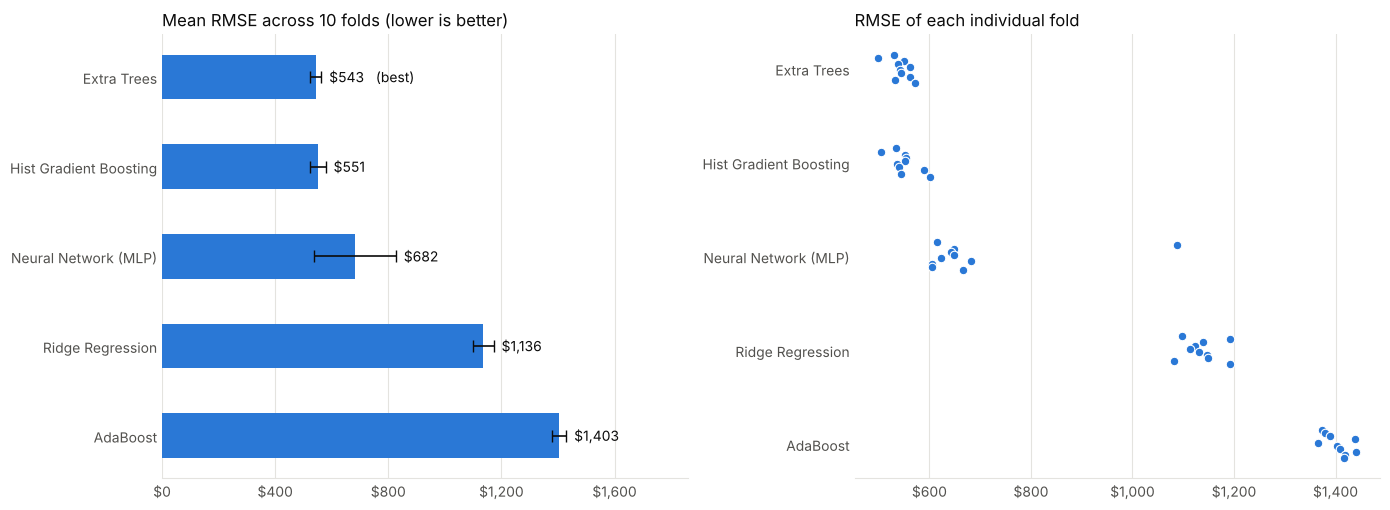

In [15]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE ($)"]
stds = summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", color=TEXT_COLOR, fontsize=12, loc="left")

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    values = per_fold_table[name].values
    jitter = np.linspace(-0.15, 0.15, len(values))
    ax2.scatter(values, i + jitter, s=38, color=BAR_COLOR, edgecolor="white", linewidth=0.8, zorder=3)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
style_axis(ax2)
ax2.set_title("RMSE of each individual fold", color=TEXT_COLOR, fontsize=12, loc="left")

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers come from my run. With different library versions they can change a little, but the pattern should stay the same.

1. **Extra Trees has the lowest mean RMSE (about $543)**, and **Hist Gradient Boosting is right behind it (about $551)**. The gap is only about $8, which is small next to the fold-to-fold standard deviation (about $20 for Extra Trees and $27 for Hist Gradient Boosting), so the two are basically tied.
2. **Trees beat the straight line.** Ridge Regression is far worse (about $1,136, more than twice the error of the top two) because the price of a diamond grows roughly exponentially with carat, which a linear formula cannot follow.
3. **AdaBoost is the weakest model (about $1,403)**, worse even than Ridge. Its 50 shallow trees are not flexible enough for this much data; it would need many more estimators or deeper trees.
4. **The neural network lands in the middle (about $682)**. It learns the curve better than Ridge but, with default settings and no tuning, it does not catch the tree models, and it is the slowest to train.
5. **Accuracy vs. speed:** Extra Trees needed about 90 seconds for the 10 folds while Hist Gradient Boosting needed under 10 seconds, roughly **10 times faster for almost the same error.**
6. **Relative error:** the best models are off by about 14% of the average price. Put differently, a typical prediction is off by about one seventh of the average price, so there is still room to improve.

# Step 10: Train the Final Model
## Step 10.1: Select the Best Algorithm

**Cross validation is used to *choose* an algorithm, it does not produce the final model.** The 10 models trained inside cross validation only measured performance and are thrown away.

The winner is the algorithm with the lowest mean RMSE.

In [16]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"Best algorithm by RMSE : {best_algorithm_name}")
print(f"Expected RMSE          : ${best_mean_rmse:,.2f} (+/- ${best_std_rmse:,.2f})")

Best algorithm by RMSE : Extra Trees
Expected RMSE          : $542.84 (+/- $20.14)


## Step 10.2: Can the Best Model Be Deployed?

Assignment Task 2 also asks me to **deploy** the model to the cloud, and a deployed model has limits that cross validation does not check. Free cloud hosting (and GitHub) only allow small files, around **100 MB** per file. Extra Trees keeps 100 fully grown trees in memory, so its saved file can be huge.

So I added a simple rule: **go down the ranking and deploy the first algorithm whose saved model file is at most 50 MB.** For each candidate the next cell trains it on all the diamonds and measures the real size of the pickled model.

In [17]:
MAX_MODEL_MB = 50

deployment_check = []
final_model = None
deployed_algorithm_name = None

for name in summary.index:                     # best RMSE first
    candidate = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", algorithms[name]),
    ])
    candidate.fit(X, y)                        # train on ALL diamonds
    size_mb = len(pickle.dumps(candidate)) / 1e6

    deployment_check.append({
        "Algorithm": name,
        "Mean RMSE ($)": summary.loc[name, "Mean RMSE ($)"],
        "Model file size (MB)": size_mb,
        "Fits the limit?": "Yes" if size_mb <= MAX_MODEL_MB else "No",
    })

    if size_mb <= MAX_MODEL_MB:
        final_model = candidate
        deployed_algorithm_name = name
        break

pd.DataFrame(deployment_check).set_index("Algorithm")

,Mean RMSE ($),Model file size (MB),Fits the limit?
Algorithm,,,
Extra Trees,542.84,682.25,No
Hist Gradient Boosting,551.05,0.37,Yes


In [18]:
deployed_rmse = summary.loc[deployed_algorithm_name, "Mean RMSE ($)"]
deployed_std = summary.loc[deployed_algorithm_name, "Std RMSE ($)"]

print(f"Algorithm chosen for deployment: {deployed_algorithm_name}")
print(f"Trained on {len(X):,} diamonds")
print(f"Expected RMSE: ${deployed_rmse:,.2f} (+/- ${deployed_std:,.2f})")

if deployed_algorithm_name != best_algorithm_name:
    extra = deployed_rmse - best_mean_rmse
    print(f"\n{best_algorithm_name} had the lowest RMSE but its model file is too big to deploy.")
    print(f"Deploying {deployed_algorithm_name} costs only ${extra:,.0f} of extra RMSE "
          f"(well inside one standard deviation of ${best_std_rmse:,.0f}).")

Algorithm chosen for deployment: Hist Gradient Boosting
Trained on 53,794 diamonds
Expected RMSE: $551.05 (+/- $27.39)

Extra Trees had the lowest RMSE but its model file is too big to deploy.
Deploying Hist Gradient Boosting costs only $8 of extra RMSE (well inside one standard deviation of $20).


## Step 10.3: Save the Trained Model

The saved file holds the **whole pipeline** (imputer, scaler, one-hot encoder *and* the algorithm), so it can predict straight from raw diamond properties. This `.pkl` file is what the web app loads. Set `DOWNLOAD_MODEL = True` to download it in Colab.

In [19]:
MODEL_FILE = "diamond_price_model.pkl"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

print(f"Trained model saved as '{MODEL_FILE}' ({os.path.getsize(MODEL_FILE) / 1e6:.2f} MB)")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Trained model saved as 'diamond_price_model.pkl' (0.37 MB)


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example diamond below so **Run all** does not stop. To type your own, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [20]:
USE_INTERACTIVE_INPUT = False

example_diamond = {
    "carat": 1.00,
    "depth": 61.8,
    "table": 57.0,
    "x": 6.40,
    "y": 6.43,
    "z": 3.97,
    "cut": "Ideal",
    "color": "G",
    "clarity": "VS2",
}

def get_diamond_input():
    print("Enter Diamond Properties (ranges seen in the data are shown):")
    for column in numeric_features:
        print(f"  {column:<7}: {X[column].min():.2f} - {X[column].max():.2f}")

    diamond = {column: float(input(f"{column}: ")) for column in numeric_features}
    for column in categorical_features:
        print(f"Allowed values for {column}: {sorted(X[column].unique())}")
        diamond[column] = input(f"{column}: ").strip()
    return diamond

user_input = get_diamond_input() if USE_INTERACTIVE_INPUT else example_diamond

print("\nDiamond to price:")
for key, value in user_input.items():
    print(f"  {key:<8}: {value}")


Diamond to price:
  carat   : 1.0
  depth   : 61.8
  table   : 57.0
  x       : 6.4
  y       : 6.43
  z       : 3.97
  cut     : Ideal
  color   : G
  clarity : VS2


## Step 11.2: Convert User Input into Feature Vector

The vector needs the **same columns in the same order** as the training data. No manual encoding is needed, the saved pipeline scales and one-hot encodes it.

In [21]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,carat,depth,table,x,y,z,cut,color,clarity
0,1.00,61.80,57.00,6.40,6.43,3.97,Ideal,G,VS2


## Step 11.3: Load the Saved Model

In [22]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'diamond_price_model.pkl': HistGradientBoostingRegressor


## Step 11.4: Model Prediction

In [23]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {deployed_algorithm_name}): about ${deployed_rmse:,.0f}")

Predicted Price: $6,194.91
Typical error (cross-validation RMSE of Hist Gradient Boosting): about $551


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (for example jewellers) is used to improve the system. Ideas for this one:

1. **Tune the hyper-parameters** of the best models (learning rate, number of iterations, tree depth) with `GridSearchCV`. All five algorithms here ran with defaults.
2. **Try a log-price target.** Diamond prices are very skewed, so predicting `log(price)` and converting back may reduce the error on cheap stones.
3. **Add more information.** Features such as certificate type (GIA / IGI), fluorescence or the seller's location are not in this dataset but affect real prices.
4. **Keep the data fresh.** This dataset is a snapshot from several years ago, so prices in a live app would drift and the model would need retraining.
5. **Report an easier-to-read error** such as MAE or percentage error next to RMSE, because RMSE is dominated by a few expensive stones.

# Conclusion

I compared **5 regression algorithms that were not used in the Car Price notebook** (Ridge Regression, AdaBoost, Extra Trees, Hist Gradient Boosting and a Neural Network) on the **full diamonds dataset (53,794 unique diamonds)** with **10-fold cross validation** and **RMSE**.

- **Extra Trees** had the lowest mean RMSE (about $543), with **Hist Gradient Boosting** almost identical (about $551). Both are far better than the neural network (about $682), Ridge Regression (about $1,136) and AdaBoost (about $1,403).
- Extra Trees produced a model file of several hundred MB, which is too large for free cloud hosting. Using a size limit of 50 MB, **Hist Gradient Boosting was trained on all the data, saved as `diamond_price_model.pkl`, and deployed** in the Streamlit web app. It is about 10 times faster to train and costs only a few dollars of extra RMSE.
- The lesson for me: the algorithm with the best score is not always the one you can ship, so size, speed and memory are part of choosing a model for deployment.